In [13]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [14]:
symbol = 'USDJPY=X'

In [15]:
data_test = yf.download(symbol, start='2020-01-01', end='2021-01-01')['Close'][symbol]
df_test = pd.DataFrame(data_test)
df_test.rename(columns={f'{symbol}': 'Close'}, inplace=True)
df_test.reset_index(inplace=True)
df_test = df_test[['Close']]
# df_test
long_period = 20
short_period = 5
df_test['MA_long'] = df_test['Close'].rolling(long_period).mean()
df_test['MA_short'] = df_test['Close'].rolling(short_period).mean()
df_test['pct_change']= abs(df_test['Close'].diff())/df_test['Close'].shift(1)
df_test.dropna(inplace=True)
df_test

n = 3

import math

df_test['MA_long_slope'] = np.degrees(np.arctan(df_test['MA_long'].diff(n))/n)
df_test['MA_short_slope'] = np.degrees(np.arctan(df_test['MA_short'].diff(n))/n)
df_test.dropna(inplace=True)
median_long_slope = abs(df_test['MA_long_slope']).median()
median_short_slope = abs(df_test['MA_short_slope']).median()
median_pct_change = abs(df_test['pct_change']).median()
# median_angle = abs(df_test['angle']).median()
# median_diff_MA = abs(df_test['diff_MA']).median()
print(f'median_long_slope: {median_long_slope}')
print(f'median_short_slope: {median_short_slope}')
print(f'median_pct_change: {median_pct_change}')
# print(f'median_ange: {median_angle}')
# print(f'median_diff_MA: {median_diff_MA}')

/tmp/ipython-input-15-1491982680.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_test = yf.download(symbol, start='2020-01-01', end='2021-01-01')['Close'][symbol]
[*********************100%***********************]  1 of 1 completed

median_long_slope: 1.9725234422795133
median_short_slope: 5.337783270219843
median_pct_change: 0.002337606855828551


/tmp/ipython-input-16-1033196637.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(symbol, start='2022-01-01', end='2025-01-01')['Close'][symbol]
[*********************100%***********************]  1 of 1 completed


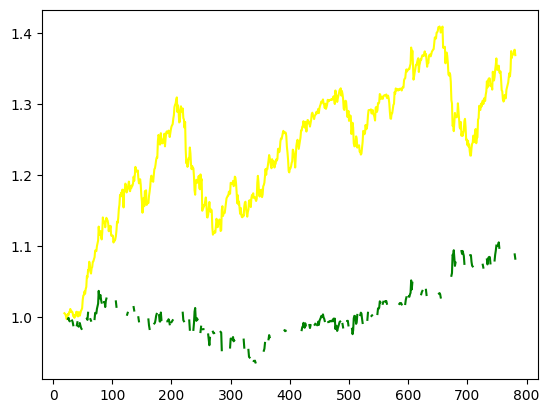

In [16]:
data = yf.download(symbol, start='2022-01-01', end='2025-01-01')['Close'][symbol]
df = pd.DataFrame(data)
df.rename(columns={f'{symbol}': 'Close'}, inplace=True)
df.reset_index(inplace=True)
df = df[['Date','Close']]
# df_test
long_period = 20
short_period = 5
df['MA_long'] = df['Close'].rolling(long_period).mean()
df['MA_short'] = df['Close'].rolling(short_period).mean()
df['pct_change'] = df['Close'].pct_change()
df.dropna(inplace=True)
df

n = 3


df['MA_long_slope'] = np.degrees(np.arctan(df['MA_long'].diff(n))/n)
df['MA_short_slope'] = np.degrees(np.arctan(df['MA_short'].diff(n))/n)
# max_short_slope_entry = 60
# Check if MAs are parallel
df['angle'] = df['MA_short_slope'] - df['MA_long_slope']
df['diff_MA'] = df['MA_short'] - df['MA_long']

df['MA_short_slope_change'] = df['MA_short_slope'].diff()
df['MA_long_slope_change'] = df['MA_long_slope'].diff()
slope_threshold_entry = 1* median_long_slope
slope_threshold_exit = median_short_slope
angle_diff_threshold = 5
position= 0

for i, row in df.iterrows():
  # if not position:
    if df.loc[i,'MA_long_slope'] > slope_threshold_entry and abs(df.loc[i,'angle']) < angle_diff_threshold:
      position = 1
      df.loc[i, 'position'] = position
      entry_price = df.loc[i,'Close']
    elif df.loc[i,'MA_long_slope'] < slope_threshold_entry  and abs(df.loc[i,'angle']) < angle_diff_threshold:
      position = -1
      df.loc[i, 'position'] = position
      entry_price = df.loc[i,'Close']
  # elif position > 0:
  #   if df.loc[i,'Close'] > 1.05 *entry_price:
  #     position = 0
  #     df.loc[i, 'position'] = position
  # elif position < 0:
  #   if df.loc[i,'MA_short_slope'] < 0.95 * entry_price:
  #     position = 0
  #     df.loc[i, 'position'] = position



# df.dropna(inplace=True)


df['strat_rets'] = df['pct_change'] * df['position'].shift(1)

cum_rets = (1 + df['pct_change']).cumprod()
cum_strat_rets = (1+ df['strat_rets']).cumprod()

plt.plot(cum_rets, color ='yellow')
plt.plot(cum_strat_rets, color = 'green')
plt.show()

